# 02 · Exploratory Data Analysis & Visualisation

Goal: understand **who is in the data**, **how ADHD and typically developing (TD) children differ**, and **what could mislead a model** before any training happens.

Contents
1. Target distribution & diagnostic subtypes
2. Site effects (a major confound)
3. Demographics: age, sex, handedness
4. Cognitive profile: IQ
5. Symptom ratings
6. Univariate statistics & effect sizes
7. Correlations & pair plots
8. Outliers
9. Low-dimensional projections (PCA, t-SNE)
10. Key insights

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

from neuroadhd.config import WEBSITE_DATA, RANDOM_STATE
from neuroadhd.data import load_clean
from neuroadhd.features import cohens_d
from neuroadhd.plotting import (savefig, PALETTE, TD_COLOR, ADHD_COLOR, CLASS_COLORS,
                                DIVERGING, INK, INK_2, MUTED, SURFACE)

df = load_clean()
df["group"] = df["adhd"].map({0: "TD", 1: "ADHD"})
print(df.shape)
df.describe().T.round(2)

(935, 23)


,count,mean,std,min,25%,50%,75%,max
participant_id,935.0,2018836.59,2324952.43,10001.00,16045.50,1585708.00,3241535.00,9956994.00
adhd,935.0,0.38,0.49,0.00,0.00,0.00,1.00,1.00
sex_male,934.0,0.62,0.49,0.00,0.00,1.00,1.00,1.00
age,935.0,11.99,3.33,7.09,9.31,11.37,13.91,26.31
handedness,926.0,0.94,0.35,-1.00,1.00,1.00,1.00,1.00
verbal_iq,635.0,112.36,14.65,65.00,103.00,112.00,122.00,158.00
performance_iq,635.0,106.33,14.56,54.00,97.00,106.00,117.00,139.00
full_iq,873.0,110.69,14.18,73.00,101.00,111.00,120.00,153.00
adhd_index,477.0,50.27,17.93,18.00,37.00,47.00,65.00,99.00
inattentive,477.0,42.08,23.08,9.00,22.00,41.00,63.00,90.00


## 1. Target distribution

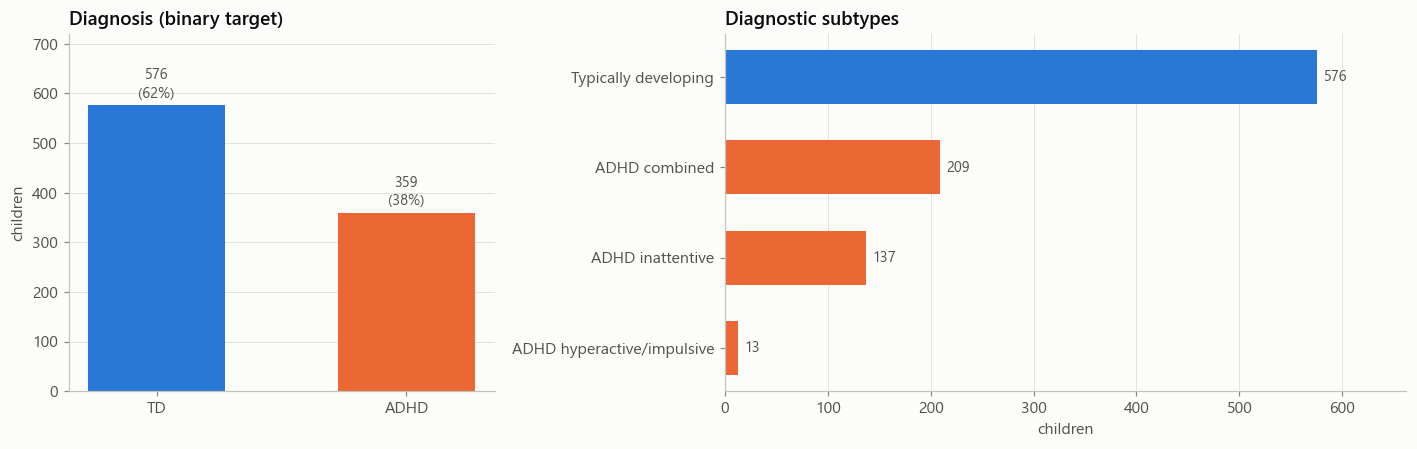

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
vc = df["group"].value_counts().reindex(["TD", "ADHD"])
ax = axes[0]
bars = ax.bar(vc.index, vc.values, color=[TD_COLOR, ADHD_COLOR], width=0.55)
for b, v in zip(bars, vc.values):
    ax.text(b.get_x() + b.get_width()/2, v + 8, f"{v}\n({v/len(df):.0%})", ha="center", va="bottom", color=INK_2, fontsize=9.5)
ax.set_ylim(0, vc.max() * 1.25); ax.set_ylabel("children"); ax.grid(axis="x", visible=False)
ax.set_title("Diagnosis (binary target)")

sub = df["dx_label"].value_counts().reindex(["TD", "ADHD-C", "ADHD-I", "ADHD-H"])
names = {"TD": "Typically developing", "ADHD-C": "ADHD combined", "ADHD-I": "ADHD inattentive", "ADHD-H": "ADHD hyperactive/impulsive"}
ax = axes[1]
cols = [TD_COLOR, ADHD_COLOR, ADHD_COLOR, ADHD_COLOR]
bars = ax.barh([names[i] for i in sub.index][::-1], sub.values[::-1], color=cols[::-1], height=0.6)
for b, v in zip(bars, sub.values[::-1]):
    ax.text(v + 6, b.get_y() + b.get_height()/2, str(v), va="center", color=INK_2, fontsize=9.5)
ax.set_xlim(0, sub.max() * 1.15); ax.grid(axis="y", visible=False); ax.set_xlabel("children")
ax.set_title("Diagnostic subtypes")
fig.tight_layout(); savefig(fig, "02_target_distribution"); plt.show()

The classes are **moderately imbalanced (≈ 62 % TD / 38 % ADHD)**: enough that accuracy alone is misleading, so we will report balanced accuracy, ROC-AUC and F1. The hyperactive/impulsive subtype is very rare (n≈11), so subtype modelling is treated as a secondary task.

## 2. Site effects

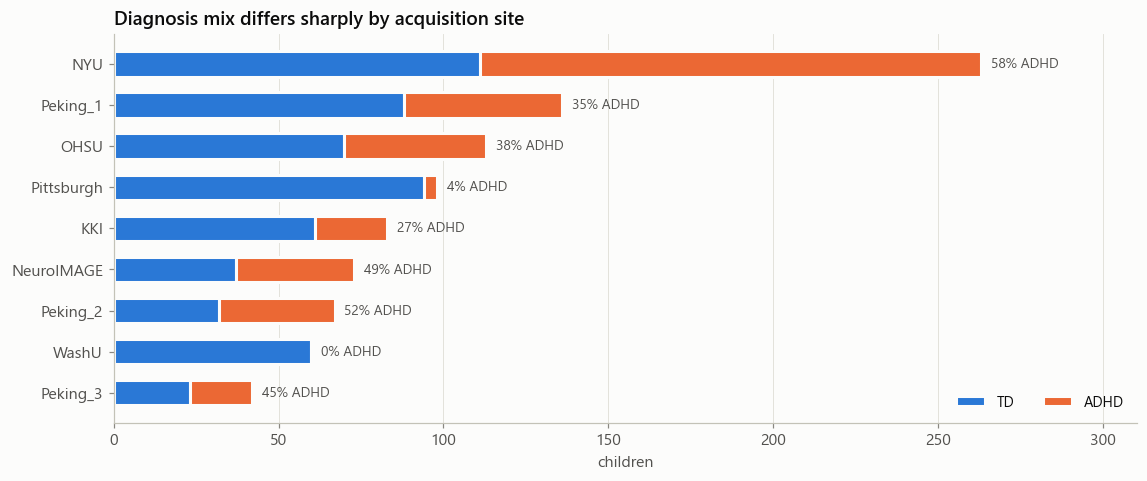

Chi-square test, site vs diagnosis: chi2=143.5, dof=8, p=4.48e-27


In [3]:
site_tab = pd.crosstab(df["site"], df["group"])[["TD", "ADHD"]]
site_tab = site_tab.loc[site_tab.sum(axis=1).sort_values().index]
fig, ax = plt.subplots(figsize=(12, 4.6))
left = np.zeros(len(site_tab))
for g, c in [("TD", TD_COLOR), ("ADHD", ADHD_COLOR)]:
    ax.barh(site_tab.index, site_tab[g], left=left, color=c, height=0.62, label=g, edgecolor=SURFACE, linewidth=2)
    left += site_tab[g].values
for i, (s, row) in enumerate(site_tab.iterrows()):
    ax.text(row.sum() + 3, i, f"{row['ADHD']/row.sum():.0%} ADHD", va="center", fontsize=9, color=INK_2)
ax.set_xlim(0, site_tab.sum(axis=1).max() * 1.18); ax.grid(axis="y", visible=False); ax.set_xlabel("children")
ax.legend(loc="lower right", ncols=2); ax.set_title("Diagnosis mix differs sharply by acquisition site")
savefig(fig, "02_site_distribution"); plt.show()

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(df["site"], df["adhd"]))
print(f"Chi-square test, site vs diagnosis: chi2={chi2:.1f}, dof={dof}, p={p:.2e}")

**Site is strongly associated with diagnosis** (WashU recruited only TD children; Pittsburgh almost only TD; NYU mostly ADHD). Any feature that encodes site (scanner, IQ test version, rating scale, age range) can let a model "predict the hospital" instead of the child. We will therefore:
- keep `site` **out** of the main feature sets,
- use **leave-one-site-out** validation to measure true generalisation.

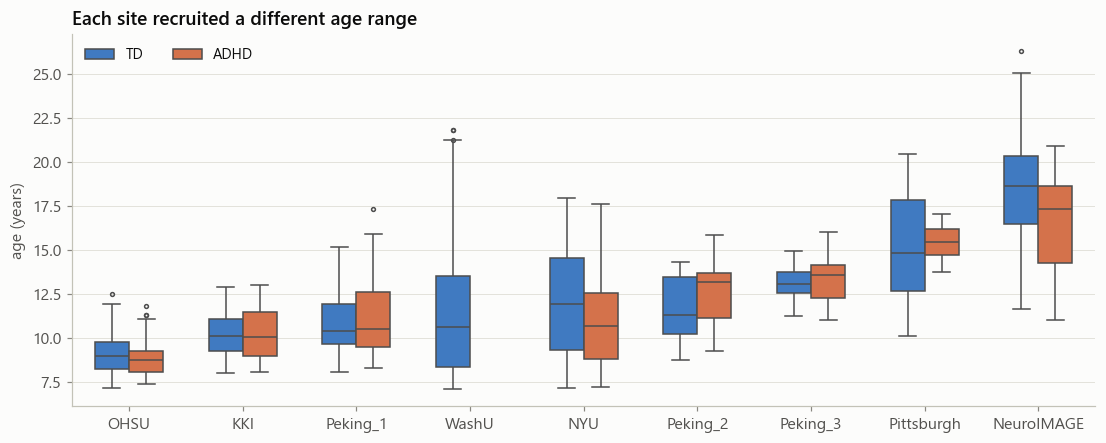

In [4]:
fig, ax = plt.subplots(figsize=(12, 4.4))
order = df.groupby("site")["age"].median().sort_values().index
sns.boxplot(data=df, x="site", y="age", hue="group", order=order, palette=CLASS_COLORS,
            hue_order=["TD", "ADHD"], width=0.6, fliersize=2.5, linewidth=1, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("age (years)"); ax.legend(title="", ncols=2, loc="upper left")
ax.set_title("Each site recruited a different age range")
savefig(fig, "02_age_by_site"); plt.show()

## 3. Demographics

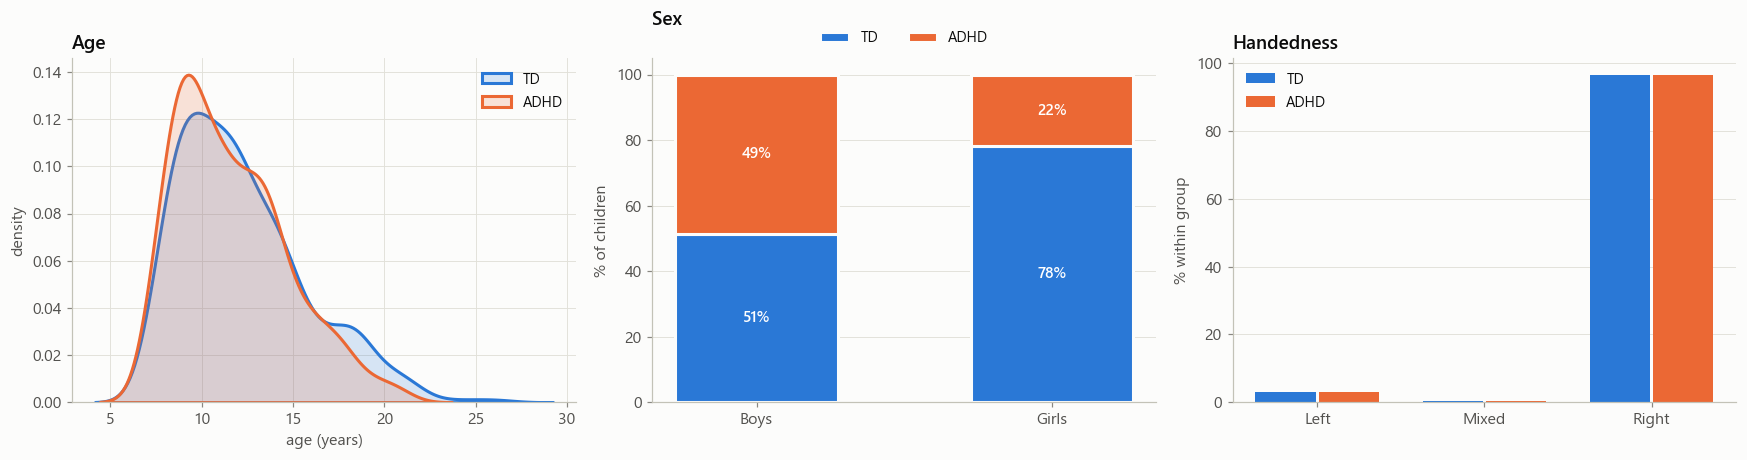

Sex vs ADHD: chi2=65.9, p=4.63e-16
ADHD rate - boys: 48.5%, girls: 21.7%


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
ax = axes[0]
for g, c in [("TD", TD_COLOR), ("ADHD", ADHD_COLOR)]:
    sns.kdeplot(df.loc[df.group == g, "age"], ax=ax, color=c, fill=True, alpha=0.18, linewidth=2, label=g)
ax.set_xlabel("age (years)"); ax.set_ylabel("density"); ax.legend(); ax.set_title("Age")

ax = axes[1]
sex = pd.crosstab(df["sex_male"].map({1: "Boys", 0: "Girls"}), df["group"], normalize="index")[["TD", "ADHD"]] * 100
bottom = np.zeros(len(sex))
for g, c in [("TD", TD_COLOR), ("ADHD", ADHD_COLOR)]:
    ax.bar(sex.index, sex[g], bottom=bottom, color=c, width=0.55, label=g, edgecolor=SURFACE, linewidth=2)
    for i, v in enumerate(sex[g]):
        ax.text(i, bottom[i] + v/2, f"{v:.0f}%", ha="center", va="center", color="white", fontsize=10, fontweight="semibold")
    bottom += sex[g].values
ax.set_ylabel("% of children"); ax.grid(axis="x", visible=False); ax.legend(ncols=2, loc="upper center", bbox_to_anchor=(0.5, 1.12))
ax.set_title("Sex", pad=22)

ax = axes[2]
hand = df.assign(h=pd.cut(df.handedness, [-1.01, -0.3, 0.3, 1.01], labels=["Left", "Mixed", "Right"]))
ht = pd.crosstab(hand.h, hand.group, normalize="columns")[["TD", "ADHD"]] * 100
x = np.arange(len(ht)); w = 0.36
ax.bar(x - w/2 - 0.01, ht["TD"], w, color=TD_COLOR, label="TD")
ax.bar(x + w/2 + 0.01, ht["ADHD"], w, color=ADHD_COLOR, label="ADHD")
ax.set_xticks(x, ht.index); ax.set_ylabel("% within group"); ax.grid(axis="x", visible=False); ax.legend()
ax.set_title("Handedness")
fig.tight_layout(); savefig(fig, "02_demographics"); plt.show()

ct = pd.crosstab(df["sex_male"], df["adhd"])
chi2, p, *_ = stats.chi2_contingency(ct)
print(f"Sex vs ADHD: chi2={chi2:.1f}, p={p:.2e}")
print(f"ADHD rate - boys: {df.loc[df.sex_male==1,'adhd'].mean():.1%}, girls: {df.loc[df.sex_male==0,'adhd'].mean():.1%}")

Boys are diagnosed far more often than girls, matching the known ~2–3 : 1 clinical ratio. Sex is therefore an informative feature, but also a reminder that models may under-detect ADHD in girls (checked in the evaluation notebook).

## 4. Cognitive profile (IQ)

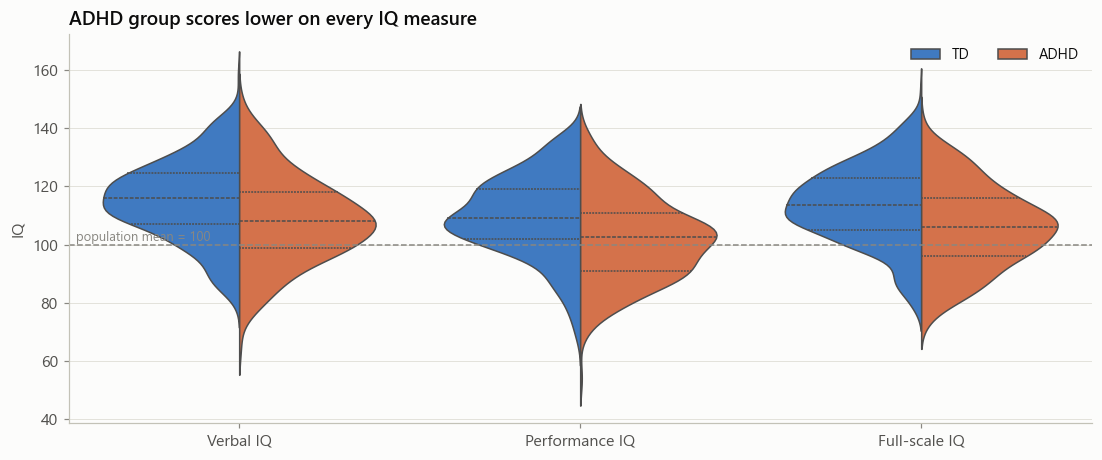

In [6]:
iq_cols = ["verbal_iq", "performance_iq", "full_iq"]
long = df.melt(id_vars="group", value_vars=iq_cols, var_name="measure", value_name="IQ").dropna()
long["measure"] = long["measure"].map({"verbal_iq": "Verbal IQ", "performance_iq": "Performance IQ", "full_iq": "Full-scale IQ"})
fig, ax = plt.subplots(figsize=(12, 4.6))
sns.violinplot(data=long, x="measure", y="IQ", hue="group", split=True, inner="quart",
               palette=CLASS_COLORS, hue_order=["TD", "ADHD"], linewidth=1, ax=ax, density_norm="width")
ax.axhline(100, color=MUTED, lw=1, ls="--"); ax.text(-0.48, 101.5, "population mean = 100", color=MUTED, fontsize=8.5, ha="left")
ax.set_xlabel(""); ax.legend(title="", loc="upper right", ncols=2)
ax.set_title("ADHD group scores lower on every IQ measure")
savefig(fig, "02_iq_violin"); plt.show()

## 5. Symptom ratings (NYU + Peking sites only)

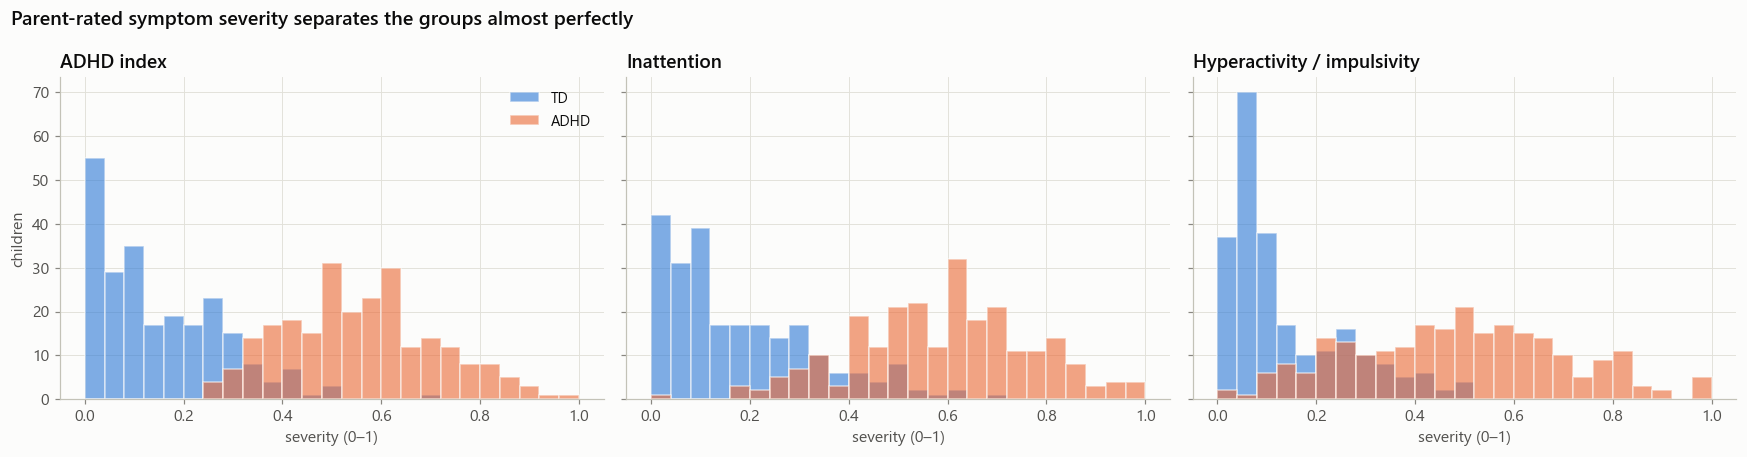

In [7]:
sym = df[df.rating_scale.notna()].copy()
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), sharey=True)
for ax, col, title in zip(axes, ["adhd_index_sev", "inattentive_sev", "hyper_impulsive_sev"],
                          ["ADHD index", "Inattention", "Hyperactivity / impulsivity"]):
    for g, c in [("TD", TD_COLOR), ("ADHD", ADHD_COLOR)]:
        ax.hist(sym.loc[sym.group == g, col], bins=np.linspace(0, 1, 26), color=c, alpha=0.6, label=g, edgecolor=SURFACE, linewidth=1)
    ax.set_title(title); ax.set_xlabel("severity (0–1)")
axes[0].set_ylabel("children"); axes[0].legend()
fig.suptitle("Parent-rated symptom severity separates the groups almost perfectly", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(); savefig(fig, "02_symptom_hist"); plt.show()

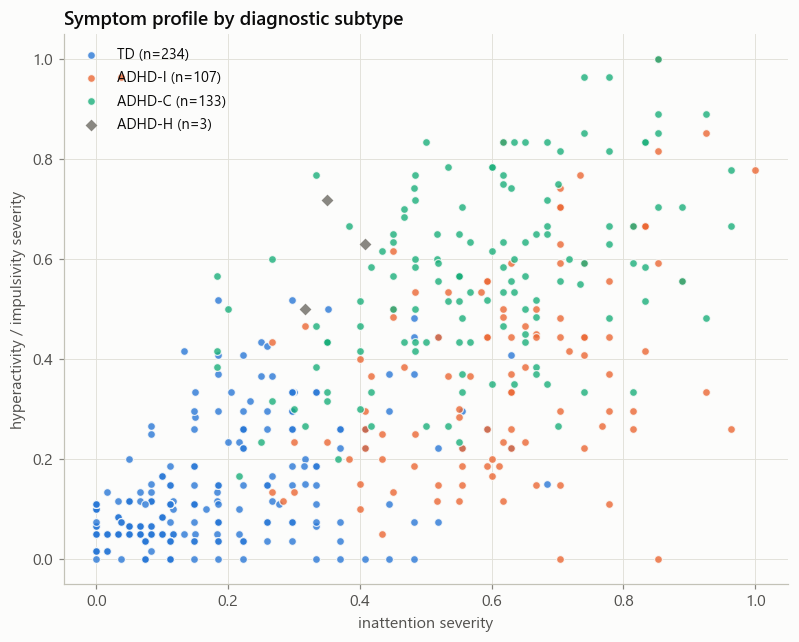

In [8]:
fig, ax = plt.subplots(figsize=(8.5, 6.5))
sub_colors = {"TD": PALETTE[0], "ADHD-I": PALETTE[1], "ADHD-C": PALETTE[2]}
for lab, c in sub_colors.items():
    s = sym[sym.dx_label == lab]
    ax.scatter(s.inattentive_sev, s.hyper_impulsive_sev, s=26, color=c, alpha=0.8, edgecolor=SURFACE, linewidth=0.8, label=f"{lab} (n={len(s)})")
s = sym[sym.dx_label == "ADHD-H"]
ax.scatter(s.inattentive_sev, s.hyper_impulsive_sev, s=30, color=MUTED, marker="D", label=f"ADHD-H (n={len(s)})")
ax.set_xlabel("inattention severity"); ax.set_ylabel("hyperactivity / impulsivity severity")
ax.legend(loc="upper left"); ax.set_title("Symptom profile by diagnostic subtype")
savefig(fig, "02_symptom_scatter"); plt.show()

The subtypes sit where the clinical definitions put them: **ADHD-I** is high on inattention only; **ADHD-C** is high on both. This is expected, since **diagnosis is partly made from these same ratings**. A model using them reaches near-perfect accuracy, but it is **reproducing the diagnostic process rather than discovering a new biomarker**. That is why the project keeps two feature sets:
- **Set A:** demographics + cognition (no symptom questionnaire), the harder and more interesting question;
- **Set B:** Set A + symptom ratings, a realistic *screening* scenario.

## 6. Univariate statistics & effect sizes

In [9]:
num_cols = ["age", "handedness", "verbal_iq", "performance_iq", "full_iq",
            "adhd_index_sev", "inattentive_sev", "hyper_impulsive_sev"]
rows = []
for c in num_cols:
    a, b = df.loc[df.adhd == 1, c].dropna(), df.loc[df.adhd == 0, c].dropna()
    t, pt = stats.ttest_ind(a, b, equal_var=False)
    u, pu = stats.mannwhitneyu(a, b)
    rows.append({"feature": c, "n_ADHD": len(a), "n_TD": len(b), "mean_ADHD": a.mean(), "mean_TD": b.mean(),
                 "cohens_d": cohens_d(a, b), "welch_t_p": pt, "mann_whitney_p": pu})
stats_df = pd.DataFrame(rows)
stats_df["bonferroni_sig"] = stats_df["mann_whitney_p"] < 0.05 / len(stats_df)
stats_df.round(4)

,feature,n_ADHD,n_TD,mean_ADHD,mean_TD,cohens_d,welch_t_p,mann_whitney_p,bonferroni_sig
0,age,359,576,11.6320,12.2172,-0.1762,0.0070,0.0275,False
1,handedness,356,570,0.9354,0.9368,-0.0042,0.9509,0.9741,False
2,verbal_iq,276,359,108.5652,115.2786,-0.4704,0.0000,0.0000,True
3,performance_iq,276,359,101.9348,109.7131,-0.5536,0.0000,0.0000,True
4,full_iq,329,544,105.8778,113.6066,-0.5650,0.0000,0.0000,True
5,adhd_index_sev,243,234,0.5565,0.1546,2.8718,0.0000,0.0000,True
6,inattentive_sev,243,234,0.5905,0.1792,2.5046,0.0000,0.0000,True
7,hyper_impulsive_sev,243,234,0.4867,0.1392,1.9848,0.0000,0.0000,True


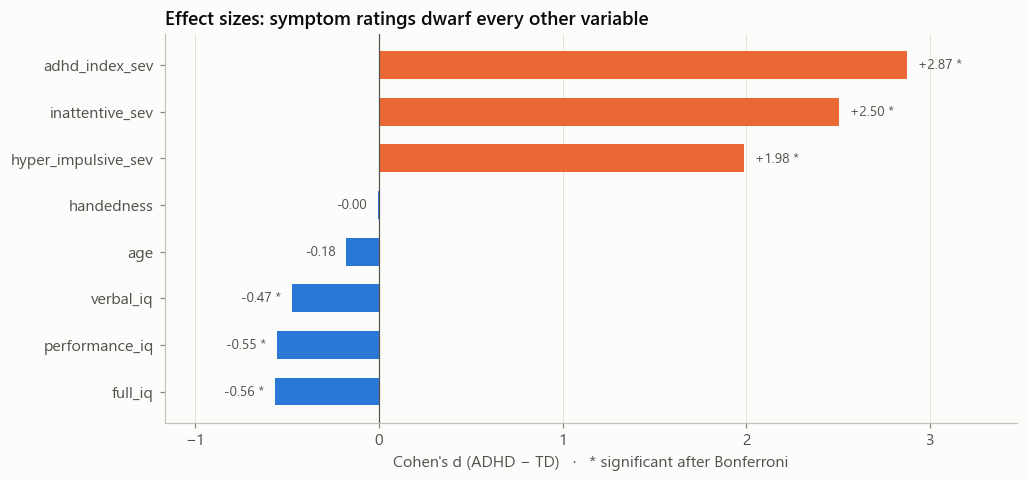

In [10]:
sd = stats_df.sort_values("cohens_d")
fig, ax = plt.subplots(figsize=(10, 4.6))
colors = [ADHD_COLOR if d > 0 else TD_COLOR for d in sd.cohens_d]
ax.barh(sd.feature, sd.cohens_d, color=colors, height=0.6)
for i, (d, sig) in enumerate(zip(sd.cohens_d, sd.bonferroni_sig)):
    ax.text(d + (0.06 if d >= 0 else -0.06), i, f"{d:+.2f}{' *' if sig else ''}", va="center",
            ha="left" if d >= 0 else "right", fontsize=9, color=INK_2)
ax.axvline(0, color=INK_2, lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlim(sd.cohens_d.min() - 0.6, sd.cohens_d.max() + 0.6)
ax.set_xlabel("Cohen's d (ADHD − TD)   ·   * significant after Bonferroni")
ax.set_title("Effect sizes: symptom ratings dwarf every other variable")
savefig(fig, "02_effect_sizes"); plt.show()

## 7. Correlations & pair plot

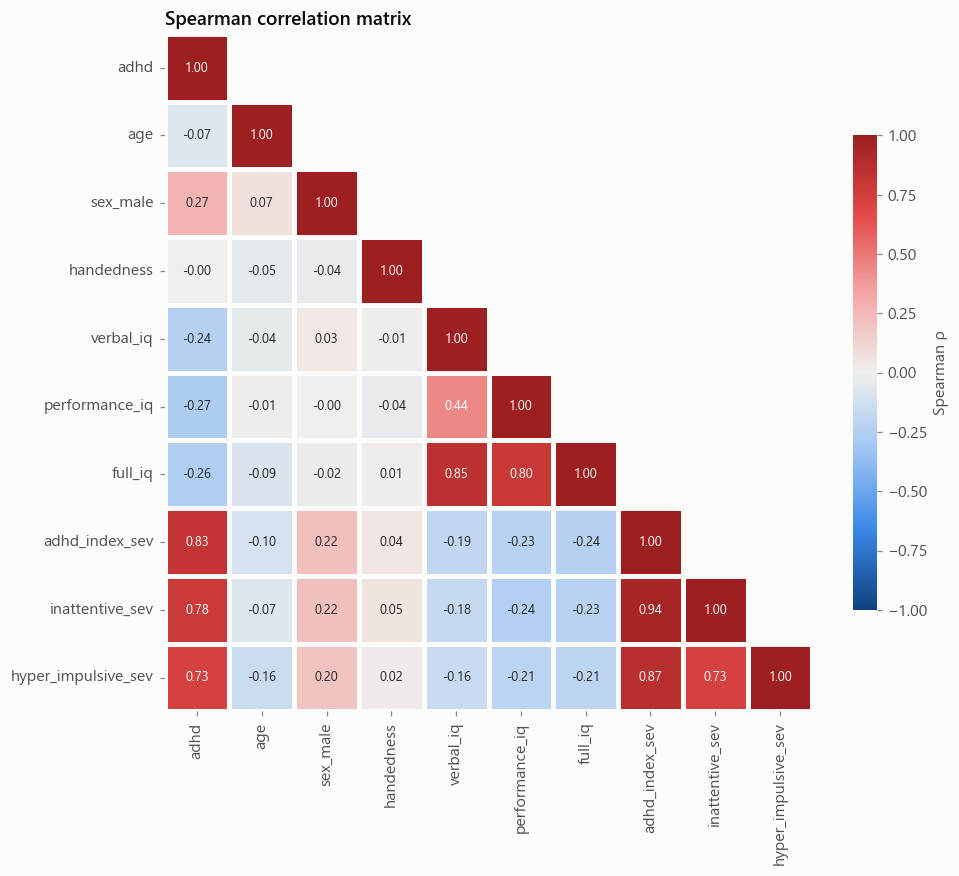

In [11]:
corr_cols = ["adhd", "age", "sex_male", "handedness", "verbal_iq", "performance_iq", "full_iq",
             "adhd_index_sev", "inattentive_sev", "hyper_impulsive_sev"]
corr = df[corr_cols].corr(method="spearman")
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
fig, ax = plt.subplots(figsize=(9.5, 8))
sns.heatmap(corr, mask=mask, cmap=DIVERGING, vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 8.5},
            linewidths=2, linecolor=SURFACE, cbar_kws={"shrink": 0.7, "label": "Spearman ρ"}, ax=ax)
ax.set_title("Spearman correlation matrix"); ax.grid(False)
savefig(fig, "02_correlation_heatmap"); plt.show()

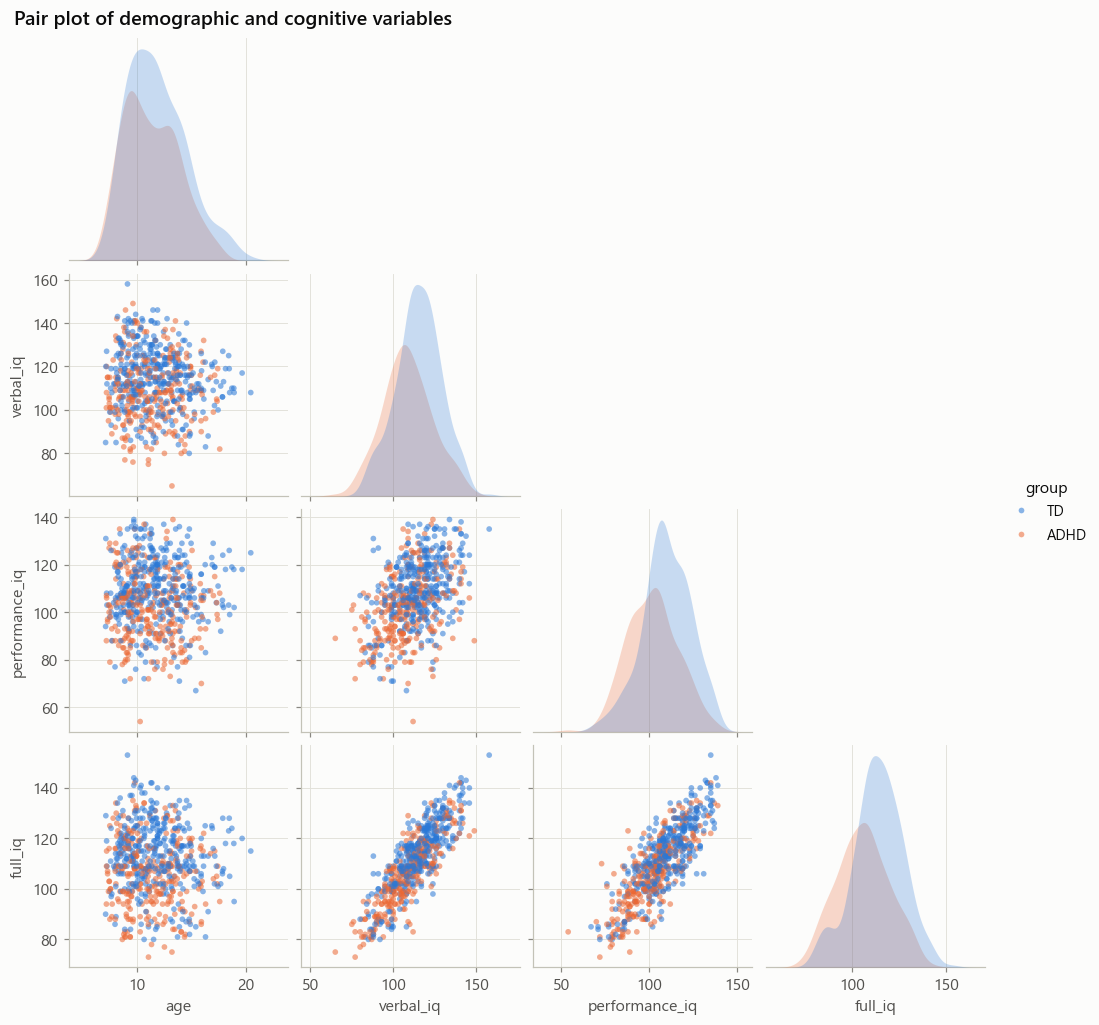

In [12]:
g = sns.pairplot(df[["age", "verbal_iq", "performance_iq", "full_iq", "group"]].dropna(), hue="group",
                 hue_order=["TD", "ADHD"], palette=CLASS_COLORS, corner=True, diag_kind="kde",
                 plot_kws={"s": 14, "alpha": 0.55, "edgecolor": "none"}, height=2.3)
g.figure.suptitle("Pair plot of demographic and cognitive variables", x=0.02, ha="left", y=1.01, fontsize=13, fontweight="semibold")
savefig(g.figure, "02_pairplot"); plt.show()

Verbal, performance and full-scale IQ are highly inter-correlated (ρ ≈ 0.6–0.9) → multicollinearity, which favours regularised linear models or tree ensembles. Without symptom ratings, no single variable separates the classes: the clouds overlap heavily.

## 8. Outliers

In [13]:
out_rows = []
for c in ["age", "verbal_iq", "performance_iq", "full_iq"]:
    x = df[c].dropna(); q1, q3 = x.quantile([.25, .75]); iqr = q3 - q1
    out_rows.append({"feature": c, "IQR_outliers": int(((x < q1 - 1.5*iqr) | (x > q3 + 1.5*iqr)).sum()),
                     "|z|>3": int((np.abs(stats.zscore(x)) > 3).sum()), "min": x.min(), "max": x.max()})
pd.DataFrame(out_rows)

,feature,IQR_outliers,|z|>3,min,max
0,age,13,3,7.09,26.31
1,verbal_iq,2,2,65.00,158.00
2,performance_iq,1,1,54.00,139.00
3,full_iq,1,0,73.00,153.00


The few extreme values (e.g. adults aged 20–26 from NeuroIMAGE, IQ scores in the 60s–150s) are **plausible**, not errors, so they are kept. Robust models (trees) and standard scaling handle them.

## 9. Low-dimensional projections

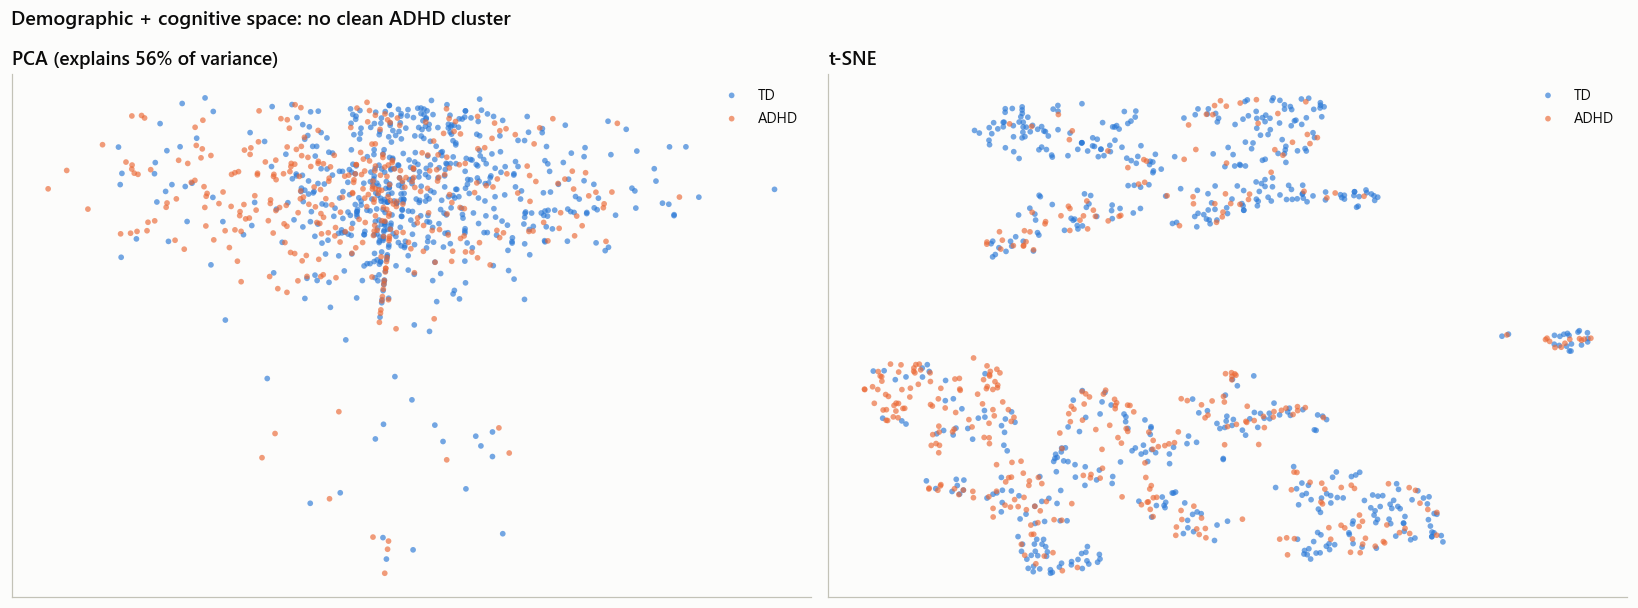

In [14]:
feats = ["age", "sex_male", "handedness", "verbal_iq", "performance_iq", "full_iq"]
X = StandardScaler().fit_transform(SimpleImputer(strategy="median").fit_transform(df[feats]))
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
Z = pca.transform(X)
tsne = TSNE(n_components=2, perplexity=35, random_state=RANDOM_STATE, init="pca").fit_transform(X)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.6))
for ax, emb, title in [(axes[0], Z, f"PCA (explains {pca.explained_variance_ratio_.sum():.0%} of variance)"),
                       (axes[1], tsne, "t-SNE")]:
    for g_, c in [("TD", TD_COLOR), ("ADHD", ADHD_COLOR)]:
        m = (df.group == g_).values
        ax.scatter(emb[m, 0], emb[m, 1], s=14, color=c, alpha=0.65, label=g_, edgecolor="none")
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([]); ax.legend()
fig.suptitle("Demographic + cognitive space: no clean ADHD cluster", x=0.01, ha="left", fontsize=13, fontweight="semibold")
fig.tight_layout(); savefig(fig, "02_projections"); plt.show()

## 10. Save a summary for the website & key insights

In [15]:
summary = {
    "n_children": int(len(df)), "n_adhd": int(df.adhd.sum()), "n_td": int((df.adhd == 0).sum()),
    "n_sites": int(df.site.nunique()), "n_with_ratings": int(df.rating_scale.notna().sum()),
    "subtypes": df.dx_label.value_counts().to_dict(),
    "site_table": {s: {"TD": int(r["TD"]), "ADHD": int(r["ADHD"])} for s, r in site_tab.iterrows()},
    "age_range": [float(df.age.min()), float(df.age.max())],
    "pct_male": float(df.sex_male.mean()),
    "effect_sizes": stats_df[["feature", "cohens_d", "mann_whitney_p"]].round(4).to_dict(orient="records"),
}
(WEBSITE_DATA / "eda_summary.json").write_text(json.dumps(summary, indent=2))
stats_df.to_csv(Path.cwd().parent / "reports" / "eda_univariate_stats.csv", index=False)
print(json.dumps({k: v for k, v in summary.items() if k not in ("effect_sizes", "site_table")}, indent=2))

{
  "n_children": 935,
  "n_adhd": 359,
  "n_td": 576,
  "n_sites": 9,
  "n_with_ratings": 477,
  "subtypes": {
    "TD": 576,
    "ADHD-C": 209,
    "ADHD-I": 137,
    "ADHD-H": 13
  },
  "age_range": [
    7.09,
    26.31
  ],
  "pct_male": 0.619914346895075
}


### Key insights
1. **Target balance:** about 38 % ADHD. Use stratified splits and imbalance-aware metrics.
2. **Site is a confounder:** the diagnosis rate ranges from 0 % to 58 % across sites. Exclude site as a feature and validate with leave-one-site-out.
3. **Sex:** boys are much more likely to be diagnosed, so it is a strong demographic predictor.
4. **IQ:** the ADHD group scores lower (medium effect, d ≈ −0.5 to −0.55), with large overlap.
5. **Symptom ratings:** huge effects (d > 2), close to defining the label. We separate the "with ratings" (Set B) and "without ratings" (Set A) scenarios.
6. **Missingness is structural** (site-dependent), so imputation must be fitted inside cross-validation.

**Next:** `03_preprocessing_feature_engineering.ipynb`